# 01. 원본 데이터 불러오기와 정리

**SEMESH for Android · 데이터 분석 1단계**

`01_load_data.py`와 같은 작업을 셀 단위로 나눠 중간 결과를 눈으로 확인하는 노트북입니다.

| 데이터 | 범위 | 이 단계에서 할 일 |
|---|---|---|
| ① HUG 지역별 전세금반환보증 사고현황 | 전국 시군구, 2026.6~8 평균 | 머리글 건너뛰기, 소계 행 제거 |
| ② HUG 서울 행정동별 경공매지원 피해주택 | 서울, 2023.7~2026.10 월별 | 인코딩 처리, 열 이름 정리 |
| ③ HUG 시군구별 경공매지원 피해주택 | 전국, 2023.7~2025 | 시트 3개 합치기, 시도/시군구 나누기 |

> 원칙: **raw 파일은 절대 수정하지 않는다.** 정리한 결과는 `data/processed/`에 따로 저장한다.

## 0. 준비: 라이브러리와 경로

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# 그래프에서 한글이 네모(□)로 깨지지 않도록 Windows 기본 한글 글꼴 지정
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False   # 한글 글꼴에서 마이너스(-) 기호 깨짐 방지

# 노트북은 analysis/notebooks/ 안에 있으므로 한 단계 위(analysis/)가 기준 폴더
BASE = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
RAW = BASE / "data" / "raw"
OUT = BASE / "data" / "processed"
OUT.mkdir(parents=True, exist_ok=True)

# raw 폴더에 어떤 파일이 있는지 먼저 확인
[p.name for p in RAW.iterdir() if p.suffix in (".xlsx", ".csv")]

['HUG_경공매지원_피해주택_소재지_시군구_20251231.xlsx',
 'HUG_서울_행정동별_경공매지원_피해주택_20261029.csv',
 'HUG_지역별_전세금반환보증_사고현황_20260831.xlsx']

## 1. 보증사고 현황 (전국 시군구, 2026.8)

### 1-1. 우선 '있는 그대로' 열어보기
정리하기 전에 원본이 어떻게 생겼는지 먼저 본다. `header=None`은 "첫 줄을 열 이름으로 쓰지 마"라는 뜻이다.

In [2]:
ACCIDENT_FILE = RAW / "HUG_지역별_전세금반환보증_사고현황_20260831.xlsx"
raw_acc = pd.read_excel(ACCIDENT_FILE, header=None)
raw_acc.head(10)

,0,1,2,3,4,5
0,전국 보증사고 현황(`26.8월),NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,광역\n지자체,기초\n지자체,보증사고('26.8.)(최근3개월),NaN,NaN
3,NaN,NaN,NaN,사고건수\n(건),사고금액\n(원),사고율\n(%)
4,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,전국,소계,813,151677813500,0.9
6,NaN,수도권,소계,575,114589497500,0.9
7,NaN,지방,소계,238,37088316000,1.1
8,11000,서울,소계,183,40236850000,0.7
9,11110,서울,종로구,6,1235000000,2


**관찰**
- 0~4행: 제목과 여러 줄로 쪼개진 머리글 → 데이터가 아니므로 `skiprows=5`로 건너뛴다.
- 5~7행의 `전국 / 수도권 / 지방 소계`, 그리고 각 시도의 `소계` 행은 **합계**다.
  시군구와 같이 두면 서울 전체가 하나의 '지역'처럼 섞여 들어가므로 제거한다.

### 1-2. 정리하기

In [3]:
acc = pd.read_excel(ACCIDENT_FILE, skiprows=5, header=None)
acc.columns = ["지역코드", "시도", "시군구", "사고건수", "사고금액", "사고율"]

# 소계(합계) 행 제거
print("제거 전:", len(acc), "행")
acc = acc[acc["시군구"] != "소계"].copy()
print("제거 후:", len(acc), "행")

# 지역코드 11110.0 → '11110' : 계산용 숫자가 아니라 지역 이름표이므로 문자열로
acc["지역코드"] = acc["지역코드"].astype(int).astype(str).str.zfill(5)

for col in ["사고건수", "사고금액", "사고율"]:
    acc[col] = pd.to_numeric(acc[col], errors="coerce").fillna(0)

acc = acc.reset_index(drop=True)
acc.head()

제거 전: 276 행
제거 후: 256 행


,지역코드,시도,시군구,사고건수,사고금액,사고율
0,11110,서울,종로구,6,1235000000,2.0
1,11140,서울,중구,4,1350000000,1.5
2,11170,서울,용산구,1,165000000,0.1
3,11200,서울,성동구,1,170000000,0.1
4,11215,서울,광진구,11,3057000000,1.8


### 1-3. 확인하기: 사고율을 그대로 믿어도 될까?
사고율이 높은 순서로 정렬해 본다.

In [4]:
acc.sort_values("사고율", ascending=False).head(10)

,지역코드,시도,시군구,사고건수,사고금액,사고율
198,46800,전남,장흥군,1,172000000,100.0
192,46710,전남,담양군,1,235000000,51.1
132,51730,강원,횡성군,1,89000000,37.9
205,46880,전남,장성군,1,100000000,33.3
241,48270,경남,밀양시,1,300000000,23.1
154,43770,충북,음성군,2,178000000,10.2
58,41500,경기,이천시,9,2711500000,8.6
239,48240,경남,사천시,6,770000000,8.0
151,43745,충북,증평군,1,170000000,6.2
72,41830,경기,양평군,3,780000000,5.5


**문제 발견** — 사고율 1위는 사고 **1건**으로 100%가 된 지역이다.
보증 가입 건수 자체가 적은 지역은 사고 한두 건만으로 비율이 크게 튄다(**작은 표본 문제**).
→ 03단계(위험등급)에서 처리 방법을 정해야 한다. 지금은 '이런 문제가 있다'는 것만 기록한다.

In [5]:
print("사고 0건 지역:", (acc["사고건수"] == 0).sum(), "곳 /", len(acc), "곳")
small = acc[(acc["사고건수"] <= 2) & (acc["사고율"] >= 10)]
print("사고 1~2건인데 사고율 10% 이상:", len(small), "곳")
small[["시도", "시군구", "사고건수", "사고율"]]

사고 0건 지역: 118 곳 / 256 곳
사고 1~2건인데 사고율 10% 이상: 6 곳


,시도,시군구,사고건수,사고율
132,강원,횡성군,1,37.9
154,충북,음성군,2,10.2
192,전남,담양군,1,51.1
198,전남,장흥군,1,100.0
205,전남,장성군,1,33.3
241,경남,밀양시,1,23.1


### 1-4. 그래프: 사고 건수 상위 15개 시군구

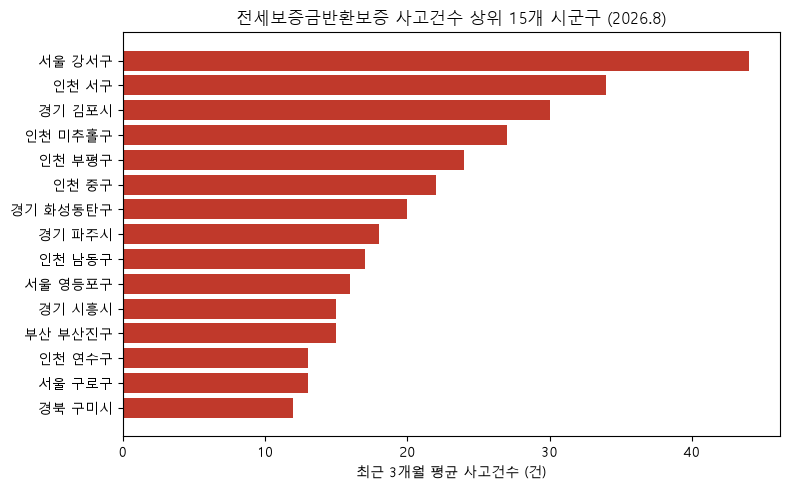

In [6]:
top = acc.sort_values("사고건수", ascending=False).head(15)
labels = top["시도"] + " " + top["시군구"]

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(labels[::-1], top["사고건수"][::-1], color="#C0392B")   # [::-1] → 1위가 맨 위로
ax.set_xlabel("최근 3개월 평균 사고건수 (건)")
ax.set_title("전세보증금반환보증 사고건수 상위 15개 시군구 (2026.8)")
plt.tight_layout()
plt.show()

서울만 있는 게 아니라 경기·인천·지방 시군구도 상위권에 나온다. → 전국 단위 분석이 의미 있다.

## 2. 서울 행정동별 피해주택 (2023.7 ~ 2026.10)

이 파일은 **UTF-8 BOM** 형식이다. 그냥 `utf-8`로 읽으면 첫 열 이름 앞에 보이지 않는 글자(`\ufeff`)가 붙어서
`df["연"]`이 에러가 난다. 그래서 `utf-8-sig`로 읽는다.

In [7]:
SEOUL_FILE = RAW / "HUG_서울_행정동별_경공매지원_피해주택_20261029.csv"
seoul = pd.read_csv(SEOUL_FILE, encoding="utf-8-sig")
seoul = seoul.rename(columns={"연": "연도", "읍면동": "행정동", "경공매지원건수": "피해건수"})
seoul.head()

,연도,월,시군구,행정동,피해건수
0,2023,7,강서구,화곡동,7
1,2023,7,구로구,오류동,1
2,2023,7,동작구,상도동,1
3,2023,8,강동구,길동,1
4,2023,8,강북구,수유동,3


In [8]:
print("행 수:", len(seoul), "/ 구:", seoul["시군구"].nunique(), "개 / 동:", seoul["행정동"].nunique(), "개")
print("총 피해건수:", seoul["피해건수"].sum())

# 연도별 합계 — 데이터 설명엔 '2025.12까지'라고 되어 있지만 실제로 2026년도 있는지 확인
seoul.groupby("연도")["피해건수"].sum()

행 수: 1263 / 구: 24 개 / 동: 219 개
총 피해건수: 1934


연도
2023    293
2024    689
2025    641
2026    311
Name: 피해건수, dtype: int64

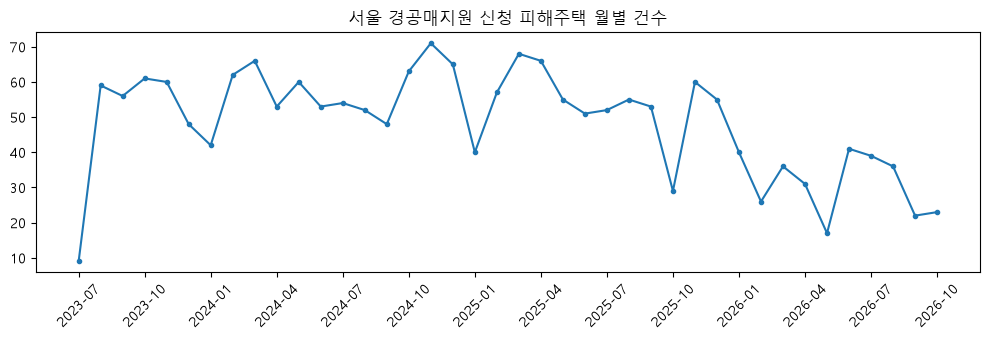

In [9]:
# 월별 추이 그래프
monthly = seoul.groupby(["연도", "월"])["피해건수"].sum().reset_index()
monthly["연월"] = monthly["연도"].astype(str) + "-" + monthly["월"].astype(str).str.zfill(2)

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(monthly["연월"], monthly["피해건수"], marker="o", markersize=3)
ax.set_xticks(monthly["연월"][::3])     # 라벨이 겹치지 않게 3개월마다 표시
ax.tick_params(axis="x", rotation=45)
ax.set_title("서울 경공매지원 신청 피해주택 월별 건수")
plt.tight_layout()
plt.show()

## 3. 시군구별 피해주택 (전국, 시트 3개)

`sheet_name=None`으로 읽으면 모든 시트를 `{시트이름: 표}` 딕셔너리로 한 번에 가져온다.

In [10]:
DAMAGE_FILE = RAW / "HUG_경공매지원_피해주택_소재지_시군구_20251231.xlsx"
sheets = pd.read_excel(DAMAGE_FILE, sheet_name=None)
{name: df.shape for name, df in sheets.items()}

{'2023년(23.7.~)': (109, 2), '2024년': (159, 2), '2025년(~25.3.)': (148, 2)}

In [11]:
frames = []
for name, df in sheets.items():
    df.columns = ["지역", "피해주택수"]
    df["기간"] = name                 # 어느 시트에서 왔는지 표시
    frames.append(df)

damage = pd.concat(frames, ignore_index=True)   # 위아래로 이어 붙이기

# '서울시 강서구' → 시도='서울시', 시군구='강서구'  (첫 번째 공백에서 한 번만 자름)
damage[["시도", "시군구"]] = damage["지역"].str.split(" ", n=1, expand=True)
damage["피해주택수"] = pd.to_numeric(damage["피해주택수"], errors="coerce").fillna(0).astype(int)
damage = damage[["기간", "시도", "시군구", "피해주택수"]]
damage.head()

,기간,시도,시군구,피해주택수
0,2023년(23.7.~),강원,속초시,2
1,2023년(23.7.~),강원,홍천군,1
2,2023년(23.7.~),경기,가평군,1
3,2023년(23.7.~),경기,광명시,2
4,2023년(23.7.~),경기,광주시,7


### 3-1. 확인 ①: '2025년(~25.3.)' 시트는 정말 3월까지일까?
같은 기관(HUG)의 서울 행정동 월별 데이터와 서울 합계를 비교해 본다.

In [12]:
seoul_in_damage = damage[damage["시도"].str.contains("서울")].groupby("기간")["피해주택수"].sum()

check = pd.DataFrame({
    "시군구 파일(서울)": seoul_in_damage.values,
    "행정동 파일: 같은 기간": [
        seoul.query("연도 == 2023 and 월 >= 7")["피해건수"].sum(),
        seoul.query("연도 == 2024")["피해건수"].sum(),
        seoul.query("연도 == 2025 and 월 <= 3")["피해건수"].sum(),
    ],
    "행정동 파일: 2025 전체": [None, None, seoul.query("연도 == 2025")["피해건수"].sum()],
}, index=seoul_in_damage.index)
check

,시군구 파일(서울),행정동 파일: 같은 기간,행정동 파일: 2025 전체
기간,,,
2023년(23.7.~),298,293,NaN
2024년,734,689,NaN
2025년(~25.3.),716,165,641.0


**결론** — 2025 시트(716건)는 1~3월(165건)보다 2025년 전체(641건)에 훨씬 가깝다.
시트 이름과 달리 **2025년 12월까지의 데이터**로 보는 것이 맞다 (파일명 `_20251231`과도 일치).
→ 논문 '데이터 전처리'에 적을 내용.

### 3-2. 확인 ②: 시도 이름이 통일되어 있을까?

In [13]:
damage["시도"].value_counts()

시도
서울시    70
경기     51
부산시    38
인천시    24
전남     20
대구시    19
강원     14
광주시    13
대전시    13
충남     13
수원시    12
경남     11
청주시    10
경북      9
고양시     9
부천시     9
성남시     9
울산시     8
용인시     8
화성시     8
창원시     7
안양시     6
안산시     6
충북      6
전주시     4
전북      4
포항시     4
세종시     3
천안시     3
제주시     2
제주      2
선안시     1
Name: count, dtype: int64

**문제 발견**
- `서울시`, `부산시`(시 붙음) ↔ `경기`, `전남`(시 없음) 표기가 섞여 있다. 보증사고 파일은 `서울`, `경기`처럼 짧은 이름을 쓴다.
- `수원시`, `고양시`, `청주시`처럼 **도(경기·충북) 없이 시 이름부터** 시작하는 행이 있다 (`수원시 장안구`).
- `세종시`, `제주시`는 시군구 칸이 비어 있고, `선안시`는 오타로 보인다(천안시?).

이대로 보증사고 데이터와 합치면 지역이 서로 맞지 않는다. → **02단계: 주소 정규화**에서 해결한다.

In [14]:
damage[damage["시군구"].isna() | damage["시도"].isin(["선안시"])]

,기간,시도,시군구,피해주택수
72,2023년(23.7.~),선안시,서북구,3
76,2023년(23.7.~),세종시,None,3
99,2023년(23.7.~),제주시,None,2
205,2024년,세종시,None,42
362,2025년(~25.3.),세종시,None,33
397,2025년(~25.3.),제주시,None,2


## 4. 저장

In [15]:
# utf-8-sig로 저장하면 엑셀에서 열어도 한글이 깨지지 않는다
acc.to_csv(OUT / "accident_2026_08.csv", index=False, encoding="utf-8-sig")
seoul.to_csv(OUT / "seoul_dong_monthly.csv", index=False, encoding="utf-8-sig")
damage.to_csv(OUT / "damage_sigungu_by_period.csv", index=False, encoding="utf-8-sig")
print("저장 완료:", [p.name for p in OUT.glob("*.csv")])

저장 완료:

 ['accident_2026_08.csv', 'damage_sigungu_by_period.csv', 'seoul_dong_monthly.csv']


## 정리

| 발견 | 처리 단계 |
|---|---|
| 사고 1~2건으로 사고율이 크게 튀는 지역 (작은 표본 문제) | 03 위험등급 |
| 2025 시트는 실제로 2025년 12월까지 | 02에서 기간 이름 수정 |
| 시도 표기 불일치, 도 이름 누락, 오타 | 02 주소 정규화 |